In [2]:
# Numerical helpers and plotting for the derivative examples below
import numpy as np
import math
import matplotlib.pyplot as plt
from graphviz import Digraph


In [3]:
#creating a class for scalar value
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._children = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, _op={self._op})"

    def __add__(self, other):
        return Value(self.data + other.data, (self, other), '+')

    def __mul__(self, other):
        return Value(self.data * other.data, (self, other), '*')

    def trace(self):
        nodes, edges = set(), set()
        def build(v):
            if v not in nodes:
                nodes.add(v)
                for child in v._children:
                    edges.add((child, v))
                    build(child)
        build(self)
        return nodes, edges

    def draw_dot(self):
        dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
        nodes, edges = self.trace()
        for n in nodes:
            uid = str(id(n))
            dot.node(name=uid, label=f"{n.label} | data: {n.data:.4f}", shape='record')
        for n1, n2 in edges:
            dot.edge(str(id(n1)), str(id(n2)))
        return dot


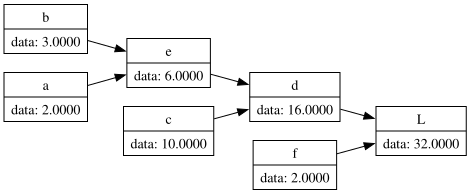

In [4]:
a = Value(2.0, label='a')
b = Value(3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(2.0, label='f')
L = d * f; L.label = 'L'
L.draw_dot()
